# Notebook 05 - Reading letters (without deep learning)

*Time: about 55-60 minutes*

## What you will learn
- The full pipeline: **picture -> gray -> blur -> Otsu -> flip -> contours -> filter -> sort**.
- How to **recognise a letter** by comparing it with a library of letter pictures (**template matching**).
- A **confidence score** that tells us how sure the computer is.
- Why **noise and tilt hurt**, and how **preprocessing** repairs the damage.

## Prerequisites
- Notebooks 03 and 04 (thresholding, contours, boxes, sorting).

## Our idea in one sentence
We cut the text into single letters, squash each into a 32 x 32 picture, and ask: *"Which of the 26 letters A-Z in my library looks most like this?"*. No artificial intelligence and no training: just pixels and arithmetic.

### What this code does

We load the libraries. `numpy` is needed to make blank canvases for our letter library.

In [1]:
import sys                                    # lets us change where Python looks for files
sys.path.append("..")                         # also look one folder up (utils.py lives there)
import cv2                                    # OpenCV
import numpy as np                            # NumPy: blank canvases
from utils import load, show_many             # our helpers
print("Libraries loaded - ready to go!")      # a visible sign that everything worked

Libraries loaded - ready to go!


### What you should see / Why we care

`Libraries loaded - ready to go!`

### What this code does

We list the three pictures we will use. **`IMAGE_PATH` is the one to change** if you want to read another picture. We load the clean one and run the recipe, showing every stage: gray, blur, Otsu (black text on white) and the flipped result (white text on black) which is our working picture `thresh`.

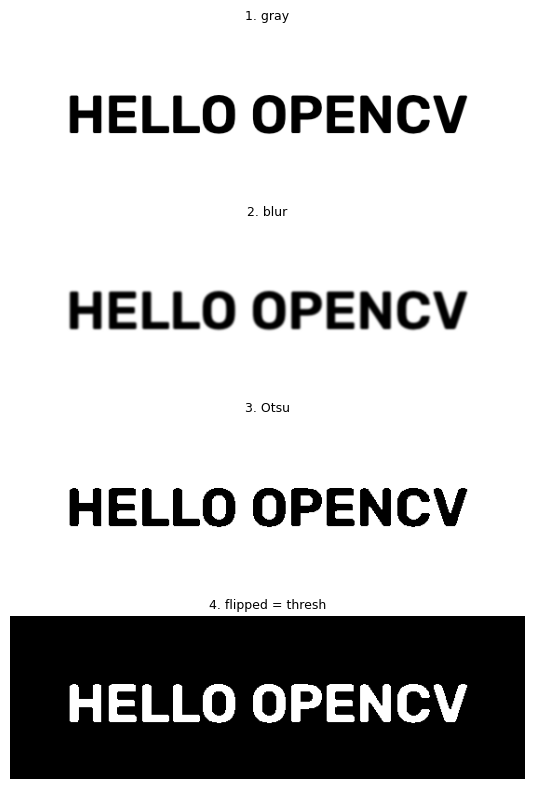

In [2]:
IMAGE_PATH = "../assets/letters_clean.png"        # <- change me to read another picture
NOISY_PATH = "../assets/letters_noisy.png"        # used later
SKEWED_PATH = "../assets/letters_skewed.png"      # used later
gray = cv2.cvtColor(load(IMAGE_PATH), cv2.COLOR_BGR2GRAY)   # 1. gray
blur = cv2.GaussianBlur(gray, (5, 5), 0)                    # 2. smooth a little
_, otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # 3. black/white
thresh = cv2.bitwise_not(otsu)                              # 4. text becomes white
show_many([gray, blur, otsu, thresh], ["1. gray", "2. blur", "3. Otsu", "4. flipped = thresh"],
          columns=1, size=(8, 8))

### What you should see / Why we care

Four stacked pictures. The last one is **white letters on black**: the form every later step needs.

### What this code does

We find the contours, keep those with an area of at least `MIN_AREA` (to ignore dust) and sort the boxes left to right. This is Notebook 04 in four lines.

In [3]:
MIN_AREA = 10                                               # ignore anything smaller than this
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
boxes = []                                                  # list of (x, y, w, h)
for contour in contours:                                    # look at every shape
    if cv2.contourArea(contour) >= MIN_AREA:                # big enough?
        boxes.append(cv2.boundingRect(contour))             # keep its box
boxes = sorted(boxes)                                       # left to right
print("letters found:", len(boxes))                         # should be 11

letters found: 11


### What you should see / Why we care

`letters found: 11`. "HELLO OPENCV" has 5 + 6 = 11 letters.

### What this code does

We cut every box out of `thresh` (slicing: `[y : y + h, x : x + w]`) and show the pieces as thumbnails. This is the **"we have segmented the characters"** moment.

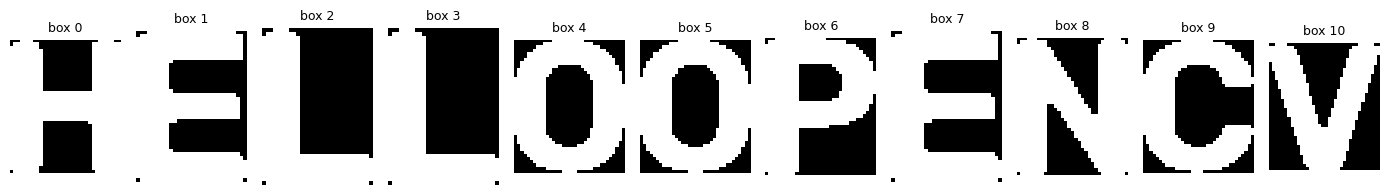

In [4]:
crops = []                                                  # one small picture per letter
titles = []                                                 # a title for each
for index in range(len(boxes)):                             # box 0, 1, 2 ...
    x, y, w, h = boxes[index]                               # its numbers
    crops.append(thresh[y:y + h, x:x + w])                  # cut it out
    titles.append("box " + str(index))                      # label it
show_many(crops, titles, columns=11, size=(14, 2))          # one row of thumbnails

### What you should see / Why we care

Eleven thumbnails, each a single white letter on black: **H E L L O O P E N C V**. The computer cannot read yet, but it has already separated the letters.

## Building a letter library (templates)

To recognise letters we need something to compare with. We make our own library by **drawing the alphabet A-Z with `cv2.putText`**. Each drawn letter is a *template*.

Because letters have different sizes (an `I` is narrow, a `W` is wide), we **squash every picture to 32 x 32 pixels** before comparing: both the templates and the letters we found.

### What this code does

`FONT` and `ALPHABET` are our settings. `tidy` is a small **function** (a named recipe): give it any cropped letter and it hands back a 32 x 32 version. `cv2.INTER_AREA` is a good way to shrink pictures.

In [5]:
FONT = cv2.FONT_HERSHEY_SIMPLEX                             # the font OpenCV can draw
ALPHABET = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"                     # all 26 letters

def tidy(crop):                                             # a recipe named tidy
    return cv2.resize(crop, (32, 32), interpolation=cv2.INTER_AREA)  # squash to 32x32

print("first crop before:", crops[0].shape, " after tidy:", tidy(crops[0]).shape)

first crop before: (41, 34)  after tidy: (32, 32)


### What you should see / Why we care

`first crop before: (41, 34)  after tidy: (32, 32)`: any letter becomes the same size.

### What this code does

For every letter: draw it in white on a black canvas, threshold it (so it is pure black and white, just like our real letters), find its tight bounding box with `cv2.boundingRect`, cut it out, and `tidy` it. We store results in a **dictionary** (`templates`), which is like a labelled drawer: `templates["A"]` gives the picture of A.

In [6]:
templates = {}                                              # an empty labelled drawer
for letter in ALPHABET:                                     # A, B, C ... Z
    canvas = np.zeros((120, 120), dtype=np.uint8)           # black canvas
    cv2.putText(canvas, letter, (20, 90), FONT, 2.5, 255, 4, cv2.LINE_AA)  # draw it white
    _, canvas = cv2.threshold(canvas, 127, 255, cv2.THRESH_BINARY)  # pure black/white
    x, y, w, h = cv2.boundingRect(canvas)                   # tight box around the letter
    templates[letter] = tidy(canvas[y:y + h, x:x + w])      # cut out, squash, store
print("templates made:", len(templates), "| picture size:", templates["A"].shape)

templates made: 26 | picture size: (32, 32)


### What you should see / Why we care

`templates made: 26 | picture size: (32, 32)`.

### What this code does

Let us *look* at our library: all 26 templates in one grid.

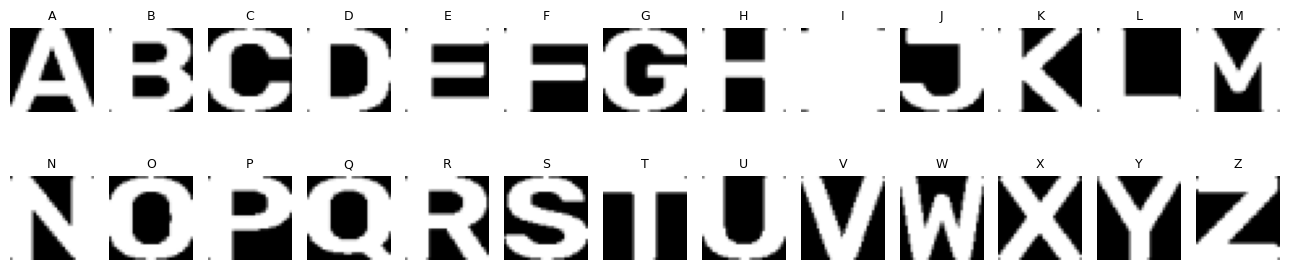

In [7]:
template_pictures = []                                      # pictures in alphabet order
for letter in ALPHABET:
    template_pictures.append(templates[letter])             # take them out of the drawer
show_many(template_pictures, list(ALPHABET), columns=13, size=(13, 3.5))

### What you should see / Why we care

The alphabet A-Z in blocky white-on-black letters. These 26 small pictures are all the computer "knows".

### What this code does

`cv2.matchTemplate(picture, template, cv2.TM_CCOEFF_NORMED)` compares a template with a picture and returns a **similarity score**: `1.0` = identical, around `0` = unrelated, negative = opposite. When both pictures have the same size (ours are 32 x 32), there is only one position to compare, so we get a single number: `[0][0]`.

We compare our first crop (the letter **H**) with three templates.

In [8]:
first_letter = tidy(crops[0])                               # our first crop at 32x32
for candidate in ["H", "E", "O"]:                           # three candidates
    result = cv2.matchTemplate(first_letter, templates[candidate], cv2.TM_CCOEFF_NORMED)
    score = result[0][0]                                    # the single similarity number
    print("similarity with", candidate, "=", round(float(score), 2))

similarity with H = 0.97
similarity with E = 0.27
similarity with O = 0.15


### What you should see / Why we care

`H` scores very high (about **0.97**), `E` and `O` score much lower. The highest score wins.

### What this code does

Now we turn "compare with one template" into a recipe that compares with **all 26** and remembers the best. `best_score` starts very low, and every time a letter scores higher, it becomes the new champion. The function returns the winning letter and its score (our **confidence**).

In [9]:
def recognize(crop, templates):                             # a recipe named recognize
    small = tidy(crop)                                      # squash the crop to 32x32
    best_letter = "?"                                       # nobody has won yet
    best_score = -1.0                                       # lower than any real score
    for letter in templates:                                # try every template
        score = cv2.matchTemplate(small, templates[letter], cv2.TM_CCOEFF_NORMED)[0][0]
        if score > best_score:                              # better than the champion?
            best_score = score                              # new champion
            best_letter = letter
    return best_letter, float(best_score)                   # winner and confidence
print("recognize() is ready:", recognize(crops[0], templates))

recognize() is ready: ('H', 0.9698712229728699)


### What you should see / Why we care

`recognize() is ready: ('H', 0.97...)`: the function names the letter and tells us how sure it is.

### What this code does

Time to read the whole picture. We loop over the sorted boxes, recognise each crop and glue the letters into a string. If the **gap** between two boxes is larger than 30% of the letter height, we insert a **space** (that is how "HELLO" and "OPENCV" are separated).

In [10]:
text = ""                                                   # the message so far
scores = []                                                 # confidence of each letter
last_right = None                                           # right edge of the previous box
for x, y, w, h in boxes:                                    # left to right
    if last_right is not None and x - last_right > 0.3 * h: # a wide gap?
        text = text + " "                                   # then it is a space
    letter, score = recognize(thresh[y:y + h, x:x + w], templates)  # read this box
    text = text + letter                                    # add the letter
    scores.append(round(score, 2))                          # remember confidence
    last_right = x + w                                      # right edge of this box
print("I read:", text)
print("confidence per letter:", scores)
print("average confidence   :", round(sum(scores) / len(scores), 2))

I read: HELLO OPENCV
confidence per letter: [0.97, 0.96, 0.99, 0.99, 0.97, 0.97, 0.97, 0.96, 0.97, 0.98, 0.97]
average confidence   : 0.97


### What you should see / Why we care

`I read: HELLO OPENCV` with confidences around **0.95 to 0.99**. We just read English letters with nothing but pixel arithmetic!

## Does it still work on bad pictures?

We now package the pipeline into **three small recipes** so we can run the *exact same code* on any picture:
1. `find_boxes(gray, use_median, min_area)`: clean, threshold, contours, boxes.
2. `read_text(thresh, boxes)`: recognise and glue the letters.
3. `accuracy(guess, truth)`: what percentage of positions are right?

### What this code does

`find_boxes` is exactly the pipeline we just built. The two extra settings let us switch the blur type and the smallest allowed area later.

In [11]:
def find_boxes(gray, use_median, min_area):                 # recipe 1
    if use_median:                                          # which blur do we want?
        blur = cv2.medianBlur(gray, 5)
    else:
        blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    thresh = cv2.bitwise_not(otsu)                          # white text on black
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []                                              # keep only big-enough shapes
    for contour in contours:
        if cv2.contourArea(contour) >= min_area:
            boxes.append(cv2.boundingRect(contour))
    return thresh, sorted(boxes)                            # left to right
test_thresh, test_boxes = find_boxes(gray, False, MIN_AREA) # try it on the clean picture
print("find_boxes() works:", len(test_boxes), "boxes")

find_boxes() works: 11 boxes


### What you should see / Why we care

`find_boxes() works: 11 boxes`

### What this code does

`read_text` is the reading loop from before, wrapped in a recipe. It returns the text and the average confidence.

In [12]:
def read_text(thresh, boxes):                               # recipe 2
    text, scores, last_right = "", [], None                 # three starting values at once
    for x, y, w, h in boxes:
        if last_right is not None and x - last_right > 0.3 * h:
            text = text + " "                               # wide gap = space
        letter, score = recognize(thresh[y:y + h, x:x + w], templates)
        text = text + letter
        scores.append(score)
        last_right = x + w
    return text, round(sum(scores) / len(scores), 2)        # text and average confidence
print("read_text() works:", read_text(thresh, boxes))

read_text() works: ('HELLO OPENCV', 0.97)


### What you should see / Why we care

`read_text() works: ('HELLO OPENCV', 0.97)`

### What this code does

`accuracy` walks through the correct answer letter by letter and counts the positions where our guess matches, then converts that to a percentage. (If the guess has extra letters, everything after them shifts and stops matching. That is exactly what we want to measure.)

In [13]:
def accuracy(guess, truth):                                 # recipe 3
    right = 0                                               # how many positions match
    for i in range(len(truth)):                             # position 0, 1, 2 ...
        if i < len(guess) and guess[i] == truth[i]:         # same letter at this position?
            right = right + 1                               # count it
    return round(100 * right / len(truth))                  # as a percentage
print("accuracy test:", accuracy("HELLO OPENCV", "HELLO OPENCV"), "%")
print("accuracy test:", accuracy("HELLO OPEWCV", "HELLO OPENCV"), "%")

accuracy test: 100 %
accuracy test: 92 %


### What you should see / Why we care

`accuracy test: 100 %` and `accuracy test: 92 %` (one wrong letter out of twelve positions).

### What this code does

**The experiment.** We run the *same* code on the three pictures (clean, noisy, tilted). `for name, path in [...]` visits each pair of a name and a file path. No special treatment: just the recipes with Gaussian blur and `min_area = 10`.

In [14]:
TRUTH = "HELLO OPENCV"                                      # the correct answer
pictures = [("clean", IMAGE_PATH), ("noisy", NOISY_PATH), ("skewed", SKEWED_PATH)]
for name, path in pictures:                                 # one picture at a time
    gray = cv2.cvtColor(load(path), cv2.COLOR_BGR2GRAY)     # load as gray
    thresh, boxes = find_boxes(gray, False, 10)             # same recipe for all
    text, conf = read_text(thresh, boxes)                   # same reader for all
    print(name.ljust(7), "| boxes:", len(boxes), "| accuracy:", accuracy(text, TRUTH), "% | confidence:", conf)
    print("        read:", text)                            # what it thought it read

clean   | boxes: 11 | accuracy: 100 % | confidence: 0.97
        read: HELLO OPENCV
noisy   | boxes: 18 | accuracy: 0 % | confidence: 0.72
        read: IHEI LLI O OPI IEI NCV I
skewed  | boxes: 11 | accuracy: 92 % | confidence: 0.63
        read: HELLO OPEWCV


### What you should see / Why we care

**Clean: 100 %.** **Noisy: 0 %** (18 boxes instead of 11, garbage text). **Skewed: 92 %**: one wrong letter (`HELLO OPEWCV`), and, more importantly, the **confidence drops** from 0.97 to 0.63. *This is the lesson of the whole notebook: the recognition step is only as good as the preprocessing before it.*

### What this code does

Why did the noisy picture fail? We draw the boxes OpenCV found on the thresholded noisy picture. (`cv2.cvtColor(..., cv2.COLOR_GRAY2BGR)` turns the gray picture into a colour one so that we can draw in colour.)

boxes found: 18 (we expected 11)


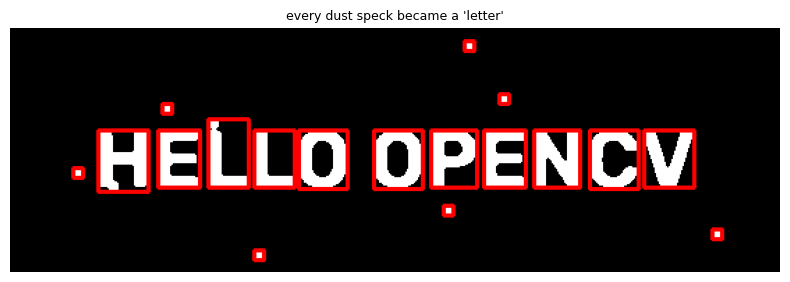

In [15]:
noisy_gray = cv2.cvtColor(load(NOISY_PATH), cv2.COLOR_BGR2GRAY)   # noisy picture in gray
noisy_thresh, noisy_boxes = find_boxes(noisy_gray, False, 10)     # same recipe as before
canvas = cv2.cvtColor(noisy_thresh, cv2.COLOR_GRAY2BGR)           # colour copy to draw on
for x, y, w, h in noisy_boxes:                                    # every box found
    cv2.rectangle(canvas, (x, y), (x + w, y + h), (0, 0, 255), 2) # red rectangle
print("boxes found:", len(noisy_boxes), "(we expected 11)")
show_many([canvas], ["every dust speck became a 'letter'"], columns=1, size=(8, 3))

### What you should see / Why we care

`boxes found: 18 (we expected 11)`. Every dust speck got a red box, so the reader tried to read dust as letters, and every letter after it shifted position.

## How much tilt can it take?

Let us measure it. We rotate the **clean** picture by different angles and read each version. (`cv2.getRotationMatrix2D` builds the rotation, `cv2.warpAffine` applies it. `borderValue=255` fills the corners with white paper.)

### What this code does

For each angle we rotate, read and print the accuracy.

In [16]:
clean_gray = cv2.cvtColor(load(IMAGE_PATH), cv2.COLOR_BGR2GRAY)   # clean picture in gray
height, width = clean_gray.shape                                  # its size
center = (width / 2, height / 2)                                  # rotate around the middle
for angle in [0, 5, 7, 10, 15]:                                   # degrees of tilt
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)          # rotation recipe
    tilted = cv2.warpAffine(clean_gray, matrix, (width, height), borderValue=255)
    thresh, boxes = find_boxes(tilted, False, 10)                 # same recipe
    text, conf = read_text(thresh, boxes)                         # same reader
    print("tilt", str(angle).rjust(2), "deg | accuracy", accuracy(text, TRUTH), "% | confidence", conf, "|", text)

tilt  0 deg | accuracy 100 % | confidence 0.97 | HELLO OPENCV
tilt  5 deg | accuracy 100 % | confidence 0.79 | HELLO OPENCV
tilt  7 deg | accuracy 100 % | confidence 0.73 | HELLO OPENCV
tilt 10 deg | accuracy 92 % | confidence 0.63 | HELLO OPEWCV
tilt 15 deg | accuracy 58 % | confidence 0.5 | BSLLO OPSSCN


### What you should see / Why we care

Small tilts (5-7 degrees) still give the right letters but the **confidence falls steadily**: the early warning. From about **10 degrees** letters start to be misread, and at 15 degrees it is a mess.

## Fixing it: preprocessing

Two repairs, both from earlier notebooks:
1. **Noisy picture:** use a **median blur** (kills grainy noise) and a bigger **area filter** (`min_area = 60` removes the dust). Median blur alone is not enough because the dust blobs are bigger than its 5 x 5 window. The area filter does that part.
2. **Tilted picture:** **deskew**: rotate the picture back by the opposite angle.

### What this code does

Same `find_boxes` and `read_text`, only with `use_median = True` and `min_area = 60`.

In [17]:
noisy_gray = cv2.cvtColor(load(NOISY_PATH), cv2.COLOR_BGR2GRAY)   # the noisy picture again
thresh, boxes = find_boxes(noisy_gray, True, 60)                  # median blur + bigger area filter
text, conf = read_text(thresh, boxes)                             # read it
print("boxes found:", len(boxes), "(expected 11)")
print("I read:", text, "| accuracy:", accuracy(text, TRUTH), "% | confidence:", conf)

boxes found: 11 (expected 11)
I read: HELLO OPENCV | accuracy: 100 % | confidence: 0.93


### What you should see / Why we care

`boxes found: 11 (expected 11)`, `I read: HELLO OPENCV`, accuracy **100 %**. The noisy picture is fixed with two small changes.

### What this code does

**Deskew.** We know this picture was tilted by 10 degrees, so we rotate it by **-10** degrees with the same two OpenCV functions, then read it again.

I read: HELLO OPENCV | accuracy: 100 % | confidence: 0.97


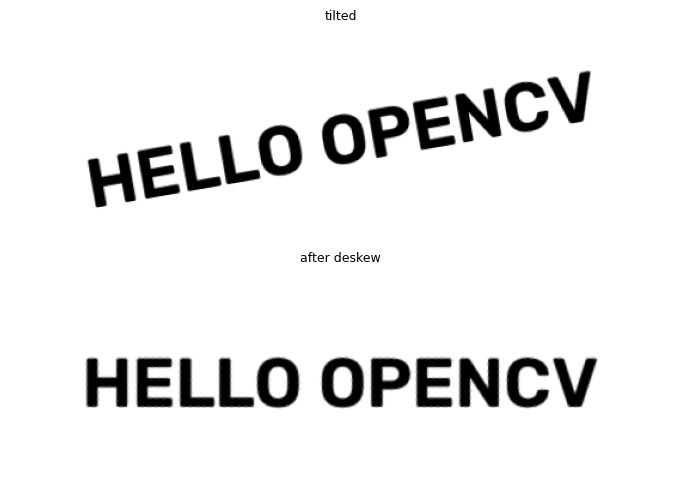

In [18]:
skewed_gray = cv2.cvtColor(load(SKEWED_PATH), cv2.COLOR_BGR2GRAY)  # the tilted picture
matrix = cv2.getRotationMatrix2D(center, -10, 1.0)                 # rotate back by 10 degrees
straight = cv2.warpAffine(skewed_gray, matrix, (width, height), borderValue=255)
thresh, boxes = find_boxes(straight, False, 10)                    # same recipe
text, conf = read_text(thresh, boxes)                              # same reader
print("I read:", text, "| accuracy:", accuracy(text, TRUTH), "% | confidence:", conf)
show_many([skewed_gray, straight], ["tilted", "after deskew"], columns=1, size=(8, 5))

### What you should see / Why we care

The text is straight again and the reading is back to **HELLO OPENCV**, with higher confidence.

**Deskew note:** in real life you do not know the angle. You can estimate it automatically (for example by measuring the slope of the text line, or by using `cv2.minAreaRect` on all the white pixels). The idea is the same: *measure the tilt, rotate back, then read*.

## Recap
- **Segmentation** (contours) + **comparison** (template matching) = a tiny reader.
- It works perfectly on **clean, upright, same-font** text.
- Confidence falls before accuracy does: **watch the confidence**.
- **Preprocessing** (median blur, area filter, deskew) rescues bad pictures.
- No machine learning anywhere. It is simply geometry and averages.

**Next:** Notebook 06 does the same for **digits**, and turns the characters into a real number you can calculate with.